In [ ]:
# Data & numerik
import pandas as pd
import numpy as np

# Visualisasi
import matplotlib.pyplot as plt

# NLP
import re
import string
import nltk
from nltk.corpus import stopwords
from nltk.stem.snowball import SnowballStemmer

# Machine Learning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


In [ ]:
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))
stemmer = SnowballStemmer("english")


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

df = pd.read_csv("/content/drive/MyDrive/dataset_movie/IMDB Dataset.csv")



Mounted at /content/drive


In [ ]:
print("===== 5 BARIS ATAS =====")
display(df.head())

print("\n===== 5 BARIS TENGAH =====")
middle = len(df) // 2
display(df.iloc[middle-2 : middle+3])

print("\n===== 5 BARIS AKHIR =====")
display(df.tail())


===== 5 BARIS ATAS =====


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive



===== 5 BARIS TENGAH =====


,review,sentiment
24998,Aah yes the workout show was a great. Not only...,positive
24999,This film should have never been made. Honestl...,negative
25000,This movie was bad from the start. The only pu...,negative
25001,"God, I never felt so insulted in my whole life...",negative
25002,Not being a fan of the Coen Brothers or George...,positive



===== 5 BARIS AKHIR =====


,review,sentiment
49995,I thought this movie did a down right good job...,positive
49996,"Bad plot, bad dialogue, bad acting, idiotic di...",negative
49997,I am a Catholic taught in parochial elementary...,negative
49998,I'm going to have to disagree with the previou...,negative
49999,No one expects the Star Trek movies to be high...,negative


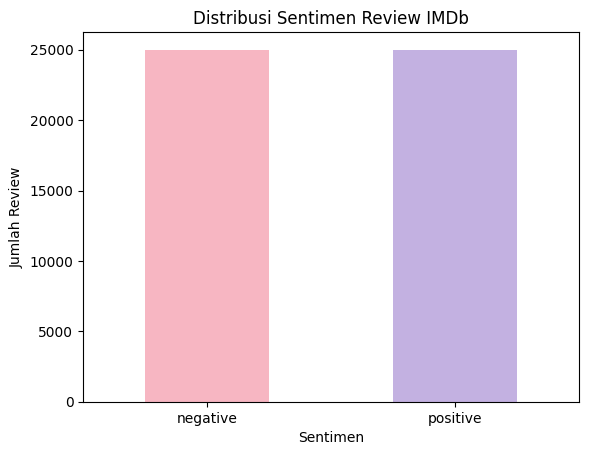

In [ ]:
sentiment_counts = df['sentiment'].value_counts().reindex(['negative', 'positive'])

sentiment_counts.plot(
    kind='bar',
    color=['#F7B6C2', '#C3B1E1'],
    title='Distribusi Sentimen Review IMDb',
    xlabel='Sentimen',
    ylabel='Jumlah Review',
    rot=0
)

plt.show()


In [ ]:
df[['review', 'clean_review']].head()



KeyError: "['clean_review'] not in index"

PRE-PROCESSING


In [ ]:
def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[%s]' % re.escape(string.punctuation), '', text)
    text = re.sub(r'\d+', '', text)
    text = text.strip()

    words = text.split()
    words = [stemmer.stem(w) for w in words if w not in stop_words]

    return " ".join(words)


In [ ]:
df['clean_review'] = df['review'].apply(preprocess_text)
df[['review', 'sentiment', 'clean_review']].head()


,review,sentiment,clean_review
0,One of the other reviewers has mentioned that ...,positive,one review mention watch oz episod youll hook ...
1,A wonderful little production. <br /><br />The...,positive,wonder littl product film techniqu unassum old...
2,I thought this was a wonderful way to spend ti...,positive,thought wonder way spend time hot summer weeke...
3,Basically there's a family where a little boy ...,negative,basic there famili littl boy jake think there ...
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,petter mattei love time money visual stun film...


In [ ]:
df['len_before'] = df['review'].astype(str).apply(lambda x: len(x.split()))
df['len_after']  = df['clean_review'].astype(str).apply(lambda x: len(x.split()))


In [ ]:
display(df[['len_before', 'len_after']].head())


,len_before,len_after
0,307,167
1,162,84
2,166,85
3,138,66
4,230,125


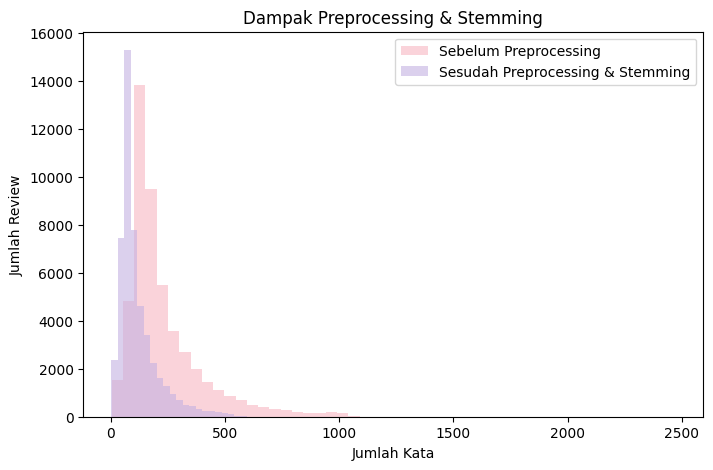

In [ ]:
plt.figure(figsize=(8,5))

plt.hist(
    df['len_before'],
    bins=50,
    alpha=0.6,
    label='Sebelum Preprocessing',
    color='#F7B6C2'
)

plt.hist(
    df['len_after'],
    bins=50,
    alpha=0.6,
    label='Sesudah Preprocessing & Stemming',
    color='#C3B1E1'
)

plt.legend()
plt.title("Dampak Preprocessing & Stemming")
plt.xlabel("Jumlah Kata")
plt.ylabel("Jumlah Review")
plt.show()


In [ ]:
df['label'] = df['sentiment'].map({'negative': 0, 'positive': 1})


FEATURE EXTRACTION

In [ ]:
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1,2)
)

X = tfidf.fit_transform(df['clean_review'])
y = df['label']


SPLIT DATA

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


NAIVE BAYYES

In [ ]:
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)


MultinomialNB()

In [ ]:
nb_model.class_log_prior_


array([-0.69314718, -0.69314718])

In [ ]:
nb_model.feature_log_prob_.shape


(2, 5000)

MATRIK

In [ ]:
y_pred = nb_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Accuracy: 0.8553

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.84      0.85      5000
           1       0.84      0.87      0.86      5000

    accuracy                           0.86     10000
   macro avg       0.86      0.86      0.86     10000
weighted avg       0.86      0.86      0.86     10000



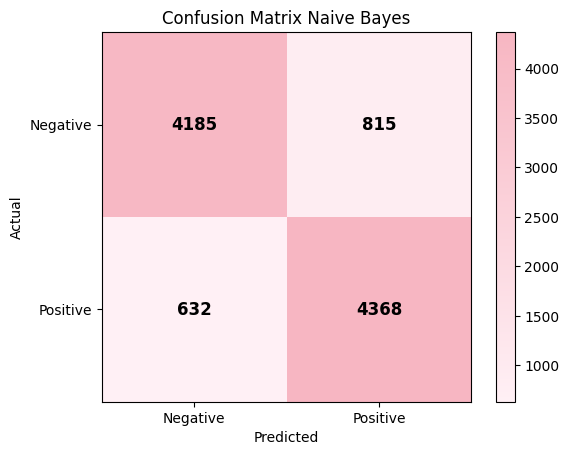

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

baby_pink = LinearSegmentedColormap.from_list(
    'baby_pink',
    ['#FFF0F5', '#F7B6C2']
)

cm = confusion_matrix(y_test, y_pred)

plt.figure()
plt.imshow(cm, cmap=baby_pink)
plt.title("Confusion Matrix Naive Bayes")
plt.colorbar()

labels = ['Negative', 'Positive']
plt.xticks([0, 1], labels)
plt.yticks([0, 1], labels)

for i in range(2):
    for j in range(2):
        plt.text(
            j, i,
            cm[i, j],
            ha='center',
            va='center',
            color='black',
            fontsize=12,
            fontweight='bold'
        )

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [ ]:
def visualize_probability(text):
    clean = preprocess_text(text)
    vector = tfidf.transform([clean])
    prob = nb_model.predict_proba(vector)[0]
    labels = ['Negative' if c == 0 else 'Positive' for c in nb_model.classes_]

    plt.figure()
    plt.bar(
        labels,
        prob,
        color=['#F7B6C2', '#C3B1E1']
    )

    plt.title("Probabilitas Sentimen (Naive Bayes)")
    plt.ylabel("Probabilitas")
    plt.ylim(0, 1)

    for i, v in enumerate(prob):
        plt.text(i, v + 0.02, f"{v:.2f}", ha='center')

    plt.show()

    return prob


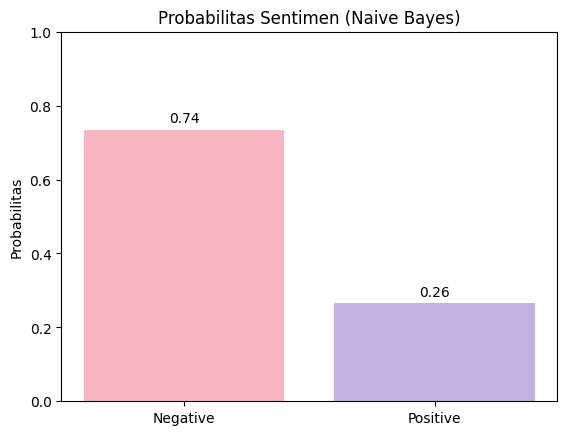

P(Negatif): 0.7350212015401053
P(Positif): 0.2649787984598956


In [ ]:
review_uji = "This movie was boring and long"
probs = visualize_probability(review_uji)

print("P(Negatif):", probs[0])
print("P(Positif):", probs[1])

INPUT BARU (NYOBA)

In [ ]:
def predict_sentiment(text):
    clean = preprocess_text(text)
    vector = tfidf.transform([clean])
    prob = nb_model.predict_proba(vector)[0]

    if prob[1] > prob[0]:
        return "SENTIMEN POSITIF"
    else:
        return "SENTIMEN NEGATIF"


In [ ]:
text = input("Masukkan review film: ")
hasil = predict_sentiment(text)
print("Hasil Analisis:", hasil)


Masukkan review film: the plot is boring and the movie is terrible
Hasil Analisis: SENTIMEN NEGATIF
